<a href="https://colab.research.google.com/github/TejasDharmale/Bayesian-machine-learning-assignment/blob/main/Bayesian_machine_learning_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



#### Name: Tejas Dharmale
#### Student Number : S1190137



##Project: III. Decision-making Under Uncertainty with Bayesian Optimization

#Overview



As the LLM training process requires several days on GPU and the company will only be able to know how to train their models (learning rate, batch size) after completing the whole process, there is no way to try all possible combinations, so the goal is to find the correct configuration in the minimum number of steps.

#Motivation
  
I slected bayesian Optimization (BO) project because the goal of BO is to find the max of an unknown function using as few expensive evaluations steps. It relies on previous data to determine the next point of evaluation. Firstly, a Gaussian Process (GP) is used as a model of the objective function which gives predictions of the value of the function at different points.


#Key idea

I will be implementing the GP model and the BO loop using JAX library.

1] First I will be testing these techniques on a 1D function for which the global maximum is known.

2] Second, then I will be choosing the GP hyperparameters by finding the values that best explain the observed data

3] Third, I investigate three ways of selecting the next sample (greedy, UCB and Thompson sampling), as well as the effect of the UCB parameter Beta on the exploration exploitation trade off.

4] Finally, I will try the same methods on the 2D Ackley function


In [ ]:
!pip install -q jaxopt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.4/172.4 kB 2.1 MB/s eta 0:00:00


In [ ]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.random as jr
import jaxopt
from jax import flatten_util
from jax.scipy.linalg import solve_triangular
jax.config.update('jax_enable_x64', True)

### 1.1 Test function and initial observations


In [ ]:

def target_func(x):

    x_val = x[:, 0]
    return jnp.sin(3 * jnp.pi * x_val) + 0.5 * jnp.sin(7 * jnp.pi * x_val)   # the function that we want to maximize

rng = jr.PRNGKey(42) #random key
rng, subkey = jr.split(rng)


X = jr.uniform(subkey, shape=(5, 1), minval=0.0, maxval=1.0)
y = target_func(X)

X_test = jnp.linspace(0, 1, 200)[:, None]   #grid where we plot the gp predictions

###1.1 Test function and initial observations
Here is above cell I have define a test function with a known formula.(sin(3πx) + 0.5 sin(7πx))
then we randomly select 5 points and evaluate the function at them

So what did I find is using a elvaluated function it helps us to test how Bayesian Optimization works and compare its predictions with the true function values

I have created 200 testing data points for comparison between the predicted and actual function value of GP on all the points.

### 1.2 Gaussian Process: kernel, posterior and prediction

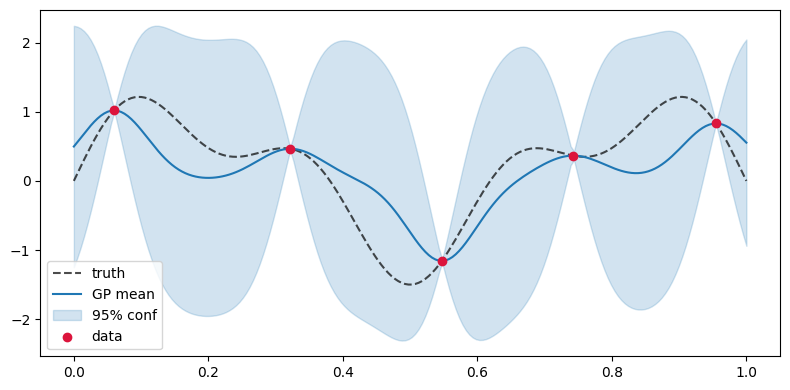

In [ ]:
def f(x):
    x_val = x[:, 0]
    return jnp.sin(3 * jnp.pi * x_val) + 0.5 * jnp.sin(7 * jnp.pi * x_val)

key = jr.PRNGKey(42)
key, subkey = jr.split(key)
X = jr.uniform(subkey, shape=(5, 1), minval=0.0, maxval=1.0)
y = f(X)

X_test = jnp.linspace(0, 1, 200)[:, None]

def rbf_kernel(x1, x2, params):
    length_scale, signal_std = params

    diff = x1[:, None, :] - x2[None, :, :]
    dist_sq = jnp.sum(diff ** 2, axis=-1)

    return (signal_std ** 2) * jnp.exp(-dist_sq / (2.0 * length_scale ** 2))

def compute_gp_posterior(train_data, X_test, kernel_fn, params, noise=1e-3):
    X_train, y_train = train_data
    N = len(X_train)

    K = kernel_fn(X_train, X_train, params)
    K = K + (noise ** 2) * jnp.eye(N)

    K_s = kernel_fn(X_train, X_test, params)
    K_ss = kernel_fn(X_test, X_test, params)

    L = jnp.linalg.cholesky(K)
    tmp = solve_triangular(L, y_train, lower=True)
    alpha = solve_triangular(L.T, tmp, lower=False)

    mean = (K_s.T @ alpha).squeeze()

    v = solve_triangular(L, K_s, lower=True)
    cov = K_ss - v.T @ v

    return mean, cov

gp_params = (jnp.array([0.05]), jnp.array([1.0]))
mu, cov_mat = compute_gp_posterior((X, y), X_test, rbf_kernel, gp_params)
std_dev = jnp.sqrt(jnp.clip(jnp.diag(cov_mat), 0.0))

plt.figure(figsize=(8, 4))
plt.plot(X_test[:, 0], f(X_test), 'k--', label='truth', alpha=0.7)
plt.plot(X_test[:, 0], mu, color='tab:blue', label='GP mean')

plt.fill_between(
    X_test[:, 0],
    mu - 2 * std_dev,
    mu + 2 * std_dev,
    color='tab:blue',
    alpha=0.2,
    label='95% conf'
)

plt.scatter(X[:, 0], y, c='crimson', zorder=5, label='data')
plt.legend(loc='best')
plt.tight_layout()
plt.show()


###1.2 Gaussian Process: kernel, posterior and prediction
The GP predicts the function value at any location along with the uncertainty.
The kernel I have used is the RBF(radial basis function) kernel (length scale 0.1 and signal std 1.0).

The posterior is estimated by using the five observations with Cholesky Decomposition.

What is Cholesky decomposition, it is used instead of directly inverting this matrix

Graph Plot: The dotted line represents the actual function, red dots represent the five observations,
blue line represents the GP mean, and blue band represents the uncertainty.

The acquisition function will use this uncertainty for making the next choice of point.

#UCB acquisition

Beta 0.0 suggests next sample at x = 0.060
Beta 2.0 suggests next sample at x = 0.121
Beta 10.0 suggests next sample at x = 0.166


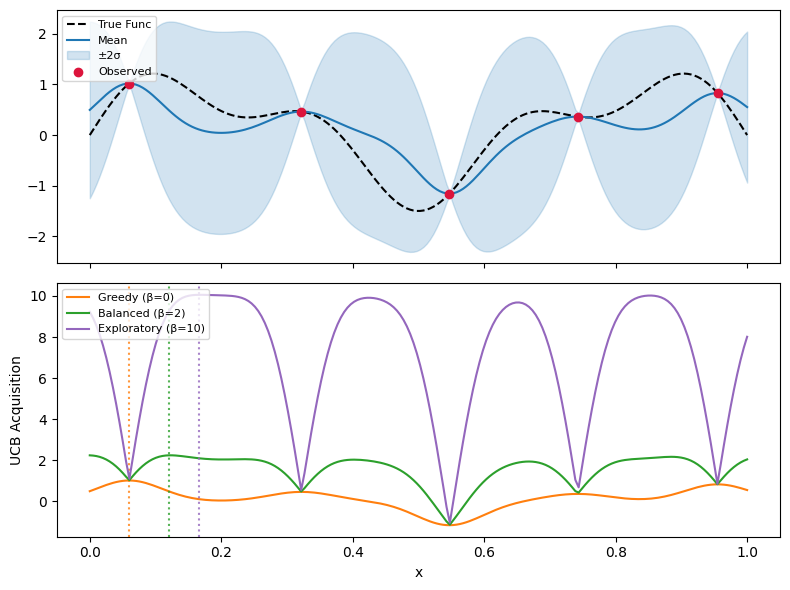

In [ ]:
sigma = jnp.sqrt(jnp.clip(jnp.diag(cov_mat), 0.0))

def calc_ucb(mean, std, weight):
    return mean + weight * std

fig, (ax_gp, ax_acq) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax_gp.plot(X_test[:, 0], f(X_test), 'k--', label='True Func')
ax_gp.plot(X_test[:, 0], mu, color='tab:blue', label='Mean')
ax_gp.fill_between(X_test[:, 0], mu - 2*sigma, mu + 2*sigma, color='tab:blue', alpha=0.2, label='±2σ')
ax_gp.scatter(X[:, 0], y, color='crimson', zorder=5, label='Observed')
ax_gp.legend(loc='upper left', fontsize=8)

beta_configs = [
    (0.0, 'tab:orange', 'Greedy (β=0)'),
    (2.0, 'tab:green', 'Balanced (β=2)'),
    (10.0, 'tab:purple', 'Exploratory (β=10)')
]

for beta, color, label_text in beta_configs:
    ucb_score = calc_ucb(mu, sigma, beta)
    best_idx = jnp.argmax(ucb_score)

    ax_acq.plot(X_test[:, 0], ucb_score, color=color, label=label_text)
    ax_acq.axvline(X_test[best_idx, 0], color=color, linestyle=':', alpha=0.8)

    print(f"Beta {beta} suggests next sample at x = {float(X_test[best_idx, 0]):.3f}")

ax_acq.legend(loc='upper left', fontsize=8)
ax_acq.set_ylabel('UCB Acquisition')
ax_acq.set_xlabel('x')

plt.tight_layout()
plt.show()


###UCB
GP provides a mean and uncertainty at all points. However, GP does not tell you which point should be evaluated next.

That's where UCB is used; basically, it turns those two numbers into one score per point. So Bayesian optimization can pick the next input and find the max value with few expensive functionevaluations.

UCB = mean + beta * std, where a higher mean favors exploitation, and a higher std deviation favors exploration, which is costly.

I used three betas: 0 (greedy), 2 (balanced), and 10 (exploratory).

Plot: The upper plot shows the GP, while the lower plot depicts the UCB value for each beta.

Thus, we can clearly see that a larger beta moves the next sample from known regions toward unknown ones.

### 3.1 The Bayesian optimization loop

#### Reference1 : https://gaussianprocess.org/gpml/chapters/RW2.pdf?utm_source
#### Reference 2: https://distill.pub/2019/visual-exploration-gaussian-processes/?utm_source
This are reference where I studied about GP and BO

β=0.0, seed=1: final regret = 0.000
   picks: [0.76, 0.18, 0.2, 0.01, 0.1, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09]
β=0.0, seed=2: final regret = 0.002
   picks: [0.92, 0.89, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9]
β=0.0, seed=3: final regret = 0.749
   picks: [0.35, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3]
β=2.0, seed=1: final regret = 0.000
   picks: [0.86, 0.07, 1.0, 0.15, 0.0, 0.77, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9]
β=2.0, seed=2: final regret = 0.000
   picks: [1.0, 0.14, 0.79, 0.0, 0.23, 0.87, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9]
β=2.0, seed=3: final regret = 0.000
   picks: [1.0, 0.53, 0.0, 0.86, 0.83, 0.91, 0.91, 0.91, 0.91, 0.91, 0.91, 0.9, 0.91, 0.9, 0.9]


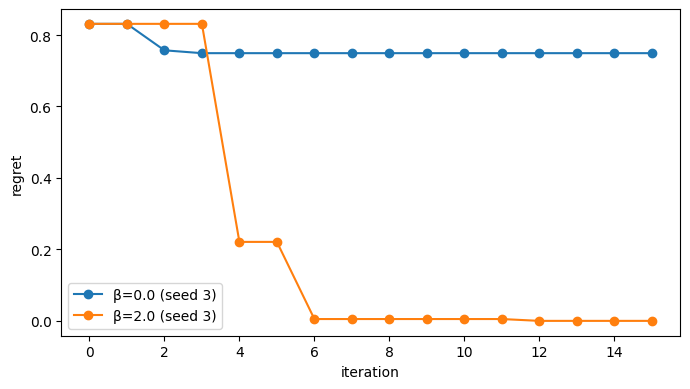

In [ ]:
def f(x):
    return jnp.sin(3 * jnp.pi * x[:, 0]) + 0.5 * jnp.sin(7 * jnp.pi * x[:, 0])

def k_SE(x1, x2, params):
    l, sigma_f = params
    diff = x1[:, None, :] - x2[None, :, :]
    return (sigma_f ** 2) * jnp.exp(-jnp.sum(diff ** 2, axis=-1) / (2 * l ** 2))

def ucb(mu, sigma, beta):
    return mu + beta * sigma

def gp_posterior(train_data, X_test, kernel, params, obs_noise=0.01):
    X_train, y_train = train_data
    n = len(X_train)
    K = kernel(X_train, X_train, params) + (obs_noise ** 2) * jnp.eye(n)
    K_s = kernel(X_train, X_test, params)
    K_ss = kernel(X_test, X_test, params)

    L = jnp.linalg.cholesky(K)
    alpha = solve_triangular(L.T, solve_triangular(L, y_train, lower=True), lower=False)

    mean = (K_s.T @ alpha).squeeze()
    v = solve_triangular(L, K_s, lower=True)
    cov = K_ss - v.T @ v
    return mean, cov

def run_bo(f, X_grid, n_init, n_iter, beta, params, key, obs_noise=0.01):
    key, subkey = jr.split(key)
    idx = jr.choice(subkey, X_grid.shape[0], (n_init,), replace=False)

    X, y = X_grid[idx], f(X_grid[idx])
    best_so_far = [float(jnp.max(y))]

    for _ in range(n_iter):
        mu, cov = gp_posterior((X, y), X_grid, k_SE, params, obs_noise)
        sigma = jnp.sqrt(jnp.clip(jnp.diag(cov), 0.0))

        x_next = X_grid[jnp.argmax(ucb(mu, sigma, beta))][None, :]
        y_next = f(x_next)

        X = jnp.concatenate([X, x_next])
        y = jnp.concatenate([y, y_next])
        best_so_far.append(float(jnp.max(y)))

    return X, y, jnp.array(best_so_far)

X_grid = jnp.linspace(0, 1, 200)[:, None]
f_max = float(jnp.max(f(X_grid)))
params = (jnp.array([0.15]), jnp.array([1.0]))

plt.figure(figsize=(7, 4))

for beta in [0.0, 2.0]:
    for seed in [1, 2, 3]:
        Xb, yb, best = run_bo(f, X_grid, n_init=3, n_iter=15, beta=beta,
                              params=params, key=jr.PRNGKey(seed))
        print(f'β={beta}, seed={seed}: final regret = {f_max - float(best[-1]):.3f}')
        print('   picks:', [round(float(v), 2) for v in Xb[3:, 0].tolist()])

    plt.plot(f_max - best, 'o-', label=f'β={beta} (seed 3)')

plt.xlabel('iteration')
plt.ylabel('regret')
plt.legend()
plt.tight_layout()
plt.show()


We use Bayesian optimization when func is expensive to evaluate so we can only afford a few steps instead of exploring more inputs to get results.

The steps used in BO are as follows:

1] First, a GP is used to predict true function f here, x is the unknown function and it tell us how uncertain this function is

2] Second step is to calculate UCB (mean + beta * uncertainty) which gives us one and from which the highest score is chosen.

3] Third and final step is to evaluate the true function f at that point

4] Finally add the result to the data and repeat loop the again.

Graph:
At Beta = 2 the process will get better through exploration which will reduce the regret to zero.

When beta = 0, the algorithm concentrates on the predictions only and gets trapped, with high regret.

### 3b. Fitting the GP hyperparameters with the marginal likelihood

In [ ]:
def f(x):
    return jnp.sin(3 * jnp.pi * x[:, 0]) + 0.5 * jnp.sin(7 * jnp.pi * x[:, 0])

def k_SE(x1, x2, params):
    l, sf = params
    return (sf ** 2) * jnp.exp(-jnp.sum((x1[:, None, :] - x2[None, :, :]) ** 2, axis=-1) / (2 * l ** 2))

def gp_posterior(data, X_test, kernel, params, noise=0.01):
    X, y = data
    K = kernel(X, X, params) + (noise ** 2) * jnp.eye(len(X))
    L = jnp.linalg.cholesky(K)
    alpha = solve_triangular(L.T, solve_triangular(L, y, lower=True), lower=False)
    K_s = kernel(X, X_test, params)
    return (K_s.T @ alpha).squeeze(), kernel(X_test, X_test, params) - solve_triangular(L, K_s, lower=True).T @ solve_triangular(L, K_s, lower=True)

def ucb(mu, sigma, beta):
    return mu + beta * sigma

def run_bo(f, X_grid, n_init, n_iter, beta, params, key, noise=0.01):
    key, subkey = jr.split(key)
    idx = jr.choice(subkey, X_grid.shape[0], (n_init,), replace=False)
    X, y = X_grid[idx], f(X_grid[idx])
    best = [float(jnp.max(y))]

    for _ in range(n_iter):
        mu, cov = gp_posterior((X, y), X_grid, k_SE, params, noise)
        sigma = jnp.sqrt(jnp.clip(jnp.diag(cov), 0.0))
        x_next = X_grid[jnp.argmax(ucb(mu, sigma, beta))][None, :]
        X, y = jnp.concatenate([X, x_next]), jnp.concatenate([y, f(x_next)])
        best.append(float(jnp.max(y)))

    return X, y, jnp.array(best)

In [ ]:
ELL_GRID = jnp.logspace(-2, 0, 40)
SF_GRID = jnp.logspace(-1, 1, 30)

def nlml(ell, sf, X, y, noise=0.01):
    K = k_SE(X, X, (ell, sf)) + (noise**2 + 1e-6) * jnp.eye(len(X))
    L = jnp.linalg.cholesky(K)
    alpha = solve_triangular(L.T, solve_triangular(L, y, lower=True), lower=False)
    return 0.5 * (y @ alpha) + jnp.sum(jnp.log(jnp.diag(L))) + 0.5 * len(X) * jnp.log(2 * jnp.pi)

def fit_hyperparams(X, y, noise=0.01):
    best_loss, best_params = jnp.inf, (1.0, 1.0)
    for ell in ELL_GRID:
        for sf in SF_GRID:
            loss = nlml(ell, sf, X, y, noise)
            if jnp.isfinite(loss) and loss < best_loss:
                best_loss, best_params = loss, (ell, sf)
    return jnp.array([best_params[0]]), jnp.array([best_params[1]])


Fitting hyperparameters...
Optimal lengthscale: 0.094 | signal std: 0.672
Running vmap for NLML curve...


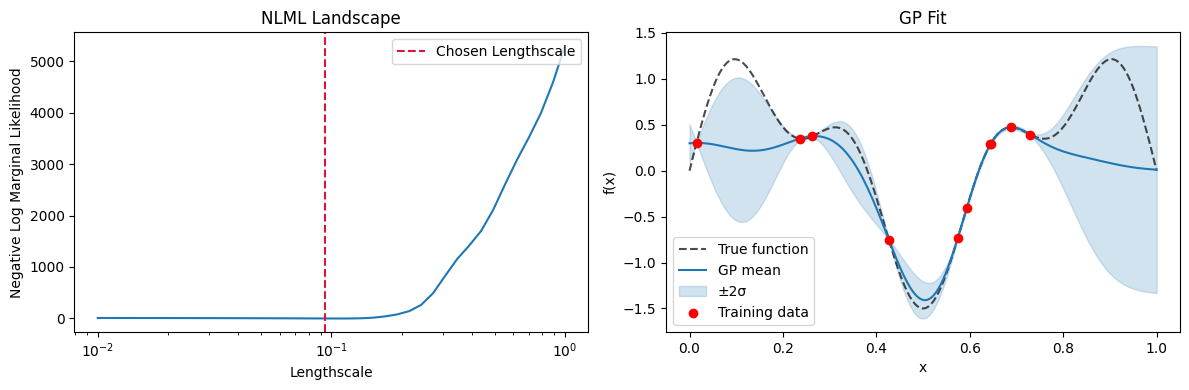

In [ ]:
key = jr.PRNGKey(42)
X10 = jr.uniform(key, (10, 1))
y10 = f(X10)

print("Fitting hyperparameters...")
best_ell, best_sf = fit_hyperparams(X10, y10)
print(f"Optimal lengthscale: {float(best_ell[0]):.3f} | signal std: {float(best_sf[0]):.3f}")

print("Running vmap for NLML curve...")
nlml_curve = jax.vmap(lambda e: nlml(e, 1.0, X10, y10))(ELL_GRID)

mu, cov_matrix = gp_posterior((X10, y10), X_test, k_SE, (best_ell, best_sf))
std_dev = jnp.sqrt(jnp.clip(jnp.diag(cov_matrix), min=0.0))

fig, (ax_nlml, ax_gp) = plt.subplots(1, 2, figsize=(12, 4))

ax_nlml.semilogx(ELL_GRID, nlml_curve, color='tab:blue')
ax_nlml.axvline(float(best_ell[0]), color='crimson', linestyle='--', label='Chosen Lengthscale')
ax_nlml.set_xlabel('Lengthscale')
ax_nlml.set_ylabel('Negative Log Marginal Likelihood')
ax_nlml.legend(loc='upper right')
ax_nlml.set_title("NLML Landscape")

ax_gp.plot(X_test[:, 0], f(X_test), 'k--', label='True function', alpha=0.7)
ax_gp.plot(X_test[:, 0], mu, color='tab:blue', label='GP mean')

upper_bound = mu + 2 * std_dev
lower_bound = mu - 2 * std_dev
ax_gp.fill_between(X_test[:, 0], lower_bound, upper_bound, color='tab:blue', alpha=0.2, label='±2σ')
ax_gp.scatter(X10[:, 0], y10, color='red', zorder=5, label='Training data')
ax_gp.set_xlabel('x')
ax_gp.set_ylabel('f(x)')
ax_gp.legend(loc='lower left')
ax_gp.set_title("GP Fit")

plt.tight_layout()
plt.show()

My goal was to choose the GP hyperparameters from the data instead of guessing them

A GP has two settings that are :

   1] lengthscale: distance by which one data point affects nearby points (small =change too quickly, large = smooth)

   2] signal std deviation: magnitude of function values

However if these values are inaccurate then the GP makes an wrong prediction. This is extremely important in BO since the UCB uses the GP’s uncertainty for making decisions about exploration, which relies on these two parameters.


Method I used are marginal likelihood. For each (lengthscale, signal std)
We take the negative logarithm of that number (NLML).

Two aspects are associated with NLML:
- The first aspect pertains to data fitting.
- The second one relates to the complexity of the model.

We test many these on many inputs of lengthscale and signal standard deviation on a grid and select the combination with the lowest NLML


Left plot:

NLML versus lengthscale. Extremely smooth functions (lengthscale is large)
cannot match the rapid variations in the data, and hence get an extremely bad NLML score

The dashed red line shows the lengthscale found by the search, around 0.094.

Right plot:

The GP fitted with these hyperparameters.

In places where we have data (0.25 and 0.75), the blue curve matches the function and the band is tight.

where there is no data (around 0 and around 1) the band is wide we can clearly in graph which means that the model is unsure there.


And the true maxima are located precisely in these regions where there is no data, so the greedy algorithm would overlook them,
but UCB prefers unknown regions and explores them

### 4. Comparing acquisition functions: greedy, UCB and Thompson sampling

Strategy: greedy --> final mean regret: 0.6060 (1/5 converged)
Strategy: ucb --> final mean regret: 0.0000 (5/5 converged)
Strategy: thompson --> final mean regret: 0.0000 (5/5 converged)


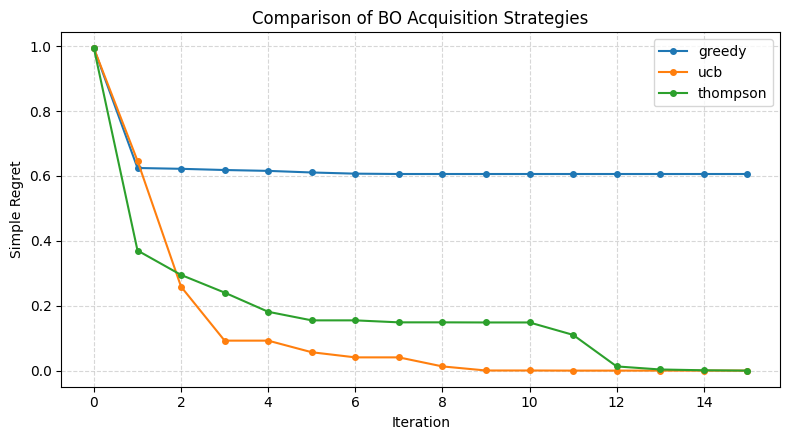

In [ ]:
def run_bo_method(objective_fn, X_pool, strategy, n_init, steps, rng_key, beta_val=2.0, noise=0.01):

    rng_key, subkey = jr.split(rng_key)
    init_idx = jr.choice(subkey, len(X_pool), (n_init,), replace=False)

    X_train = X_pool[init_idx]
    y_train = objective_fn(X_train)


    best_history = [float(jnp.max(y_train))]

    for step in range(steps):

        gp_params = fit_hyperparams(X_train, y_train, noise)
        mu, cov_mat = gp_posterior((X_train, y_train), X_pool, k_SE, gp_params, noise)


        std_dev = jnp.sqrt(jnp.clip(jnp.diag(cov_mat), 0.0))

        rng_key, subkey = jr.split(rng_key)


        if strategy == "greedy":
            acquisition = mu
        elif strategy == "ucb":
            acquisition = mu + beta_val * std_dev
        else:
            acquisition = jr.multivariate_normal(
                subkey, mu, cov_mat + 1e-6 * jnp.eye(len(mu)), method="eigh"
            )

        # select next point to evaluate
        next_idx = jnp.argmax(acquisition)
        x_new = X_pool[next_idx][None, :]

        # update our training sets
        X_train = jnp.concatenate([X_train, x_new])
        y_train = jnp.concatenate([y_train, objective_fn(x_new)])

        best_history.append(float(jnp.max(y_train)))

    return jnp.array(best_history)


strategies = ["greedy", "ucb", "thompson"]
n_seeds = 5

plt.figure(figsize=(8, 4.5))

for strat in strategies:
    all_regrets = []

    for seed_val in range(n_seeds):
        best_vals = run_bo_method(
            f, X_grid, strat, n_init=3, steps=15, rng_key=jr.PRNGKey(seed_val)
        )
        all_regrets.append(f_max - best_vals)

    all_regrets = jnp.stack(all_regrets)
    mean_regret = all_regrets.mean(axis=0)


    successes = int((all_regrets[:, -1] < 0.01).sum())
    print(f"Strategy: {strat} --> final mean regret: {float(mean_regret[-1]):.4f} ({successes}/{n_seeds} converged)")

    plt.plot(mean_regret, marker='o', markersize=4, label=strat)

plt.title("Comparison of BO Acquisition Strategies")
plt.xlabel("Iteration")
plt.ylabel("Simple Regret")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In this section I compared three ways of choosing the next point in Bayesian optimization

Same loop for all fit the GP and then it score all candidates then evaluate f at the best one and finally iterate.

Only the score differs:

 **Greedy**: mean only (pure exploitation).

  **UCB**: mean + 2 * uncertainty (rewards unexplored regions).

  **Thompson**: maximum of one random function drawn from the GP posterior.

At every step the hyperparameters uses all data collected up to that point. I use five random initializations for each algorithm and take the average of all outcomes

Results that I got is greedy final regret 0.606 (1/5 found the maximum), UCB 0.000 (5/5), Thompson 0.000 (5/5).

Graph clearly show us that greedy drops once and stays flat at about 0.6, because it gets stuck on a local peak.This is exploitation

UCB falls steadily to 0 by around iteration 9. Thompson drops fastest at first, pauses,
and reaches 0 at about iteration 12, since its exploration is random.

Conclusion we can draw: exploration is necessary. UCB and Thompson reliably find the global maximum,
while greedy does not. but with 5 runs only we cannot rank UCB and Thompson

### 5. Effect of β: from exploitation to exploration

beta: -1.0 -> final regret: 0.366
beta: 0.0 -> final regret: 0.303
beta: 0.5 -> final regret: 0.074
beta: 2.0 -> final regret: 0.000
beta: 5.0 -> final regret: 0.000
beta: 10.0 -> final regret: 0.000


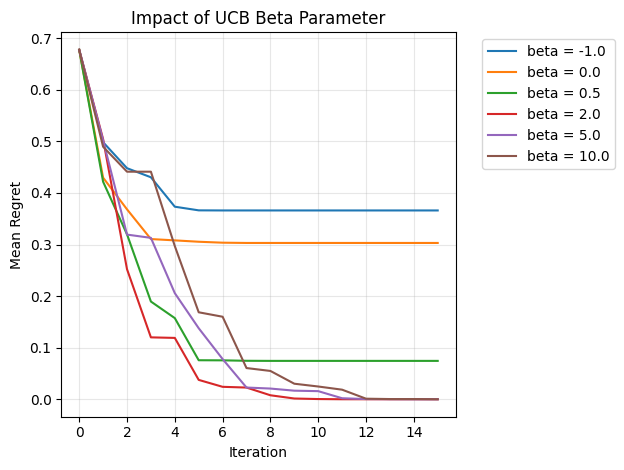

In [ ]:
# let's see how changing beta affects UCB (negative beta = crazy, high beta = super exploratory)
for beta in [-1.0, 0.0, 0.5, 2.0, 5.0, 10.0]:
    regrets = []

    for seed in range(10):
        best_values = run_bo_method(
            f, X_grid, "ucb", 3, 15, jr.PRNGKey(seed), beta_val=beta
        )
        regrets.append(f_max - best_values)

    regrets = jnp.stack(regrets)
    mean_regret = regrets.mean(axis=0)

    print(f"beta: {beta} -> final regret: {float(mean_regret[-1]):.3f}")

    plt.plot(mean_regret, label=f"beta = {beta}")

plt.title("Impact of UCB Beta Parameter")
plt.xlabel("Iteration")
plt.ylabel("Mean Regret")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

 Our main Objective here was to examine the effect of changing the value of beta on the exploitation and exploration trade off in UCB.

UCB score = mean + beta * uncertainty.

Beta values are tested from 10 different starting points and their regret values are then averaged.

Plot graph: Beta values of -1 and 0 stop getting better soon (regret around 0.37 and 0.30) since they either avoid or disregard the uncertainty part and end up in a local maximum.

A negative beta value is the worst choice. Beta of 0.5 is close (around 0.07) but still remains constant.

 The best beta value is 2 and converges to zero after iteration 9. Betas of 5 and 10 also converge to zero after iterations 11 to 12, respectively, since they focus on uncertain areas.

Summary I reached: If there is too much exploration convergence is delayed. If there is too little exploration, it will get stuck.

### 6. Bayesian optimization on the Ackley function (2D)

In [ ]:
def run_bo_method(f, X_grid, method, n_init, n_iter, key, beta=2.0, obs_noise=0.01, norm=False):

    key, subkey = jr.split(key)
    init_idx = jr.choice(subkey, len(X_grid), (n_init,), replace=False)

    X = X_grid[init_idx]
    y = f(X)


    best_vals = [float(jnp.max(y))]

    for i in range(n_iter):

        if norm:
            yn = (y - y.mean()) / (y.std() + 1e-8)
        else:
            yn = y

        gp_params = fit_hyperparams(X, yn, obs_noise)
        mu, cov_mat = gp_posterior((X, yn), X_grid, k_SE, gp_params, obs_noise)

        sigma = jnp.sqrt(jnp.clip(jnp.diag(cov_mat), 0.0))

        key, subkey = jr.split(key)

        # acquisition function choice
        if method == "greedy":
            acq = mu
        elif method == "ucb":
            acq = mu + beta * sigma
        else:
            jitter = 1e-6 * jnp.eye(len(mu))
            acq = jr.multivariate_normal(
                subkey, mu, cov_mat + jitter, method="eigh"
            )


        next_idx = jnp.argmax(acq)
        x_new = X_grid[next_idx][None, :]

        X = jnp.concatenate([X, x_new])
        y = jnp.concatenate([y, f(x_new)])

        current_best = float(jnp.max(y))
        best_vals.append(current_best)

    return jnp.array(best_vals)

Max value found on grid: -0.0000


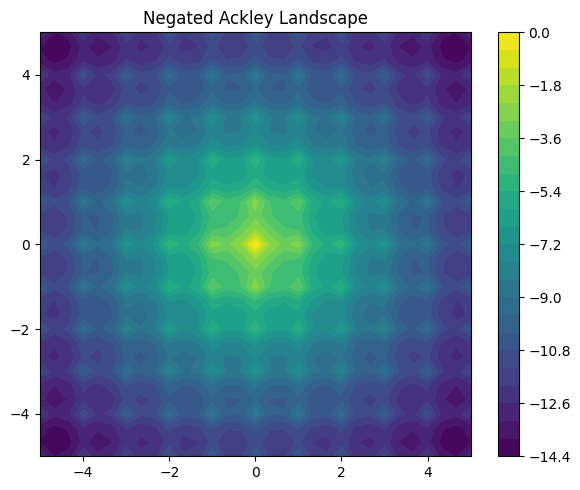

[GREEDY] Final Regret: 5.522 | Converged: 1/5
[UCB] Final Regret: 0.471 | Converged: 4/5
[THOMPSON] Final Regret: 2.083 | Converged: 2/5


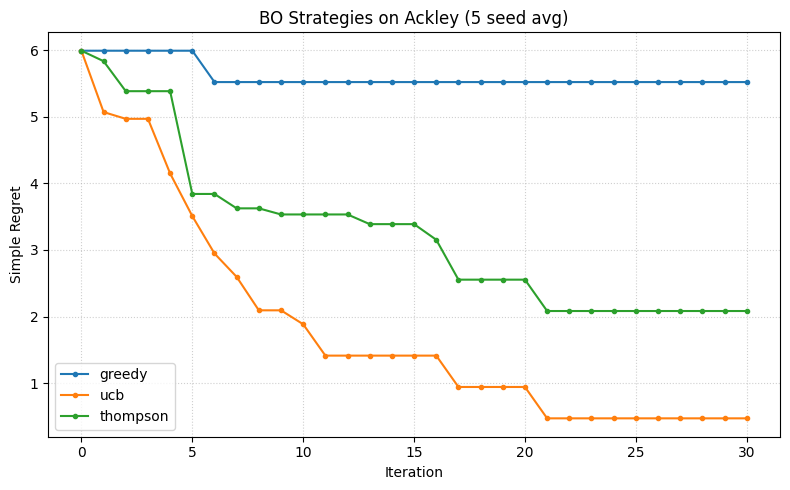

In [ ]:
# define 2D ackley
def ackley(X):
    x1, x2 = X[:, 0], X[:, 1]
    term1 = -20 * jnp.exp(-0.2 * jnp.sqrt((x1**2 + x2**2) / 2))
    term2 = -jnp.exp((jnp.cos(2*jnp.pi*x1) + jnp.cos(2*jnp.pi*x2)) / 2)
    return -(term1 + term2 + 20 + jnp.e)


g = jnp.linspace(-5, 5, 31)
G1, G2 = jnp.meshgrid(g, g)
X2 = jnp.stack([G1.ravel(), G2.ravel()], axis=1)


grid_vals = ackley(X2)
a_max = jnp.max(grid_vals)
print(f"Max value found on grid: {a_max:.4f}")


plt.figure(figsize=(6, 5))
plt.contourf(G1, G2, grid_vals.reshape(31, 31), levels=25, cmap="viridis")
plt.colorbar()
plt.title("Negated Ackley Landscape")
plt.tight_layout()
plt.show()

methods = ["greedy", "ucb", "thompson"]
n_runs = 5

plt.figure(figsize=(8, 5))

for m in methods:
    all_regrets = []

    for s in range(n_runs):
        best_vals = run_bo_method(
            ackley, X2, m, n_init=5, n_iter=30, key=jr.PRNGKey(s), norm=True
        )
        all_regrets.append(a_max - best_vals)

    all_regrets = jnp.stack(all_regrets)
    mean_regret = all_regrets.mean(axis=0)


    converged = int((all_regrets[:, -1] < 0.01).sum())
    print(f"[{m.upper()}] Final Regret: {float(mean_regret[-1]):.3f} | Converged: {converged}/{n_runs}")

    plt.plot(mean_regret, marker='o', markersize=3, label=m)

plt.title("BO Strategies on Ackley (5 seed avg)")
plt.xlabel("Iteration")
plt.ylabel("Simple Regret")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

Comparing acquisition strategies for Bayesian optimization on the 2D Ackley function

Basically Ackely function is a test function that is used to check how well an optimazation  algo finds the best maximum

Initial setup: Ackley is negated so that the BO loop can maximize it.

The global maximum is 0, which occurs at (0,0). Many local maxima surround the global maximum. Since I know the actual maximum, I can quantify my regret as the difference between the actual maximum and the maximum that I have found to date.


Results I got are(mean over 5 seeds, 30 iterations each)

**UCB**:      final regret 0.47, converged in 4/5 runs

**Thompson**: final regret 2.08, converged in 2/5 runs

**Greedy**:   final regret 5.52, converged in 1/5 runs

Only Greedy algorithm takes into account GP mean, so it picks up the first good peak and
does not bother to sample unknown regions.

For UCB algorithm, there is an exploration bonus beta * sigma, thus it keeps exploring until it reaches the central peak.

The Thompson sampling is explorative as well, but using posterior samples instead. Using only 30 evaluations might make it expensive.

I made the 3d visualization to see how ackley function works.

###Ackley function (3D) Visualization (Extra)

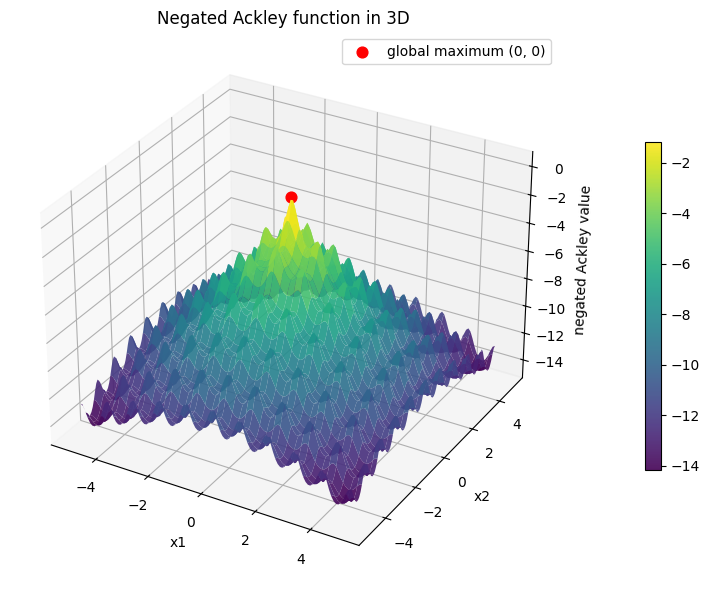

In [ ]:
# define 2D ackley function to ensure it is available in this cell
def ackley(X):
    x1, x2 = X[:, 0], X[:, 1]
    term1 = -20 * jnp.exp(-0.2 * jnp.sqrt((x1**2 + x2**2) / 2))
    term2 = -jnp.exp((jnp.cos(2*jnp.pi*x1) + jnp.cos(2*jnp.pi*x2)) / 2)
    return -(term1 + term2 + 20 + jnp.e)


fine = jnp.linspace(-5, 5, 120)
F1, F2 = jnp.meshgrid(fine, fine)


points = jnp.stack([F1.ravel(), F2.ravel()], axis=1)
Z = ackley(points).reshape(F1.shape)

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(np.asarray(F1), np.asarray(F2), np.asarray(Z),
                       cmap="viridis", edgecolor="none", alpha=0.9)
ax.scatter([0], [0], [0], color="red", s=60, label="global maximum (0, 0)")

ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("negated Ackley value")
ax.set_title("Negated Ackley function in 3D")
ax.view_init(elev=30, azim=-60)

fig.colorbar(surf, shrink=0.6, pad=0.1)
ax.legend()
plt.tight_layout()
plt.show()



In [ ]:
# Conclusion that we can draw from our observation is one high and steep peak at the center (global optimum) along with many small peaks (local optima) that exist in the whole area of the square.
# The climbing algorithm will be confined within the first local optimum that it comes across; that is why the search is important for this function.

### 7. Kernel choice and fully Bayesian hyperparameters

In [ ]:
def k_matern52(x1, x2, params):
    ell, sf = params

    diff = x1[:, None, :] - x2[None, :, :]
    dist = jnp.sqrt(jnp.sum(diff**2, axis=-1) + 1e-12) / ell

    factor = 1.0 + jnp.sqrt(5.0) * dist + (5.0 / 3.0) * (dist**2)
    return (sf**2) * factor * jnp.exp(-jnp.sqrt(5.0) * dist)


def nlml(ell, sf, X, y, kernel, obs_noise=0.01):
    K = kernel(X, X, (ell, sf))
    K += (obs_noise**2 + 1e-6) * jnp.eye(len(X))

    L = jnp.linalg.cholesky(K)

    alpha = solve_triangular(L.T, solve_triangular(L, y, lower=True), lower=False)


    data_fit = 0.5 * y @ alpha
    complexity = jnp.sum(jnp.log(jnp.diag(L)))
    constant = 0.5 * len(X) * jnp.log(2 * jnp.pi)

    return data_fit + complexity + constant

kernels_to_test = [("SE", k_SE), ("Matérn 5/2", k_matern52)]

print("Starting hyperparameter tuning grid search...")
for name, kernel in kernels_to_test:
    scores = []
    for ell in ELL_GRID:
        row = [nlml(ell, sf, X10, y10, kernel) for sf in SF_GRID]
        scores.append(row)

    scores = jnp.array(scores)


    best_flat_idx = jnp.argmin(scores)
    best_i, best_j = jnp.unravel_index(best_flat_idx, scores.shape)

    best_ell = ELL_GRID[best_i]
    best_sf = SF_GRID[best_j]
    min_loss = scores[best_i, best_j]

    print(f"--> {name} Optimal -> lengthscale: {float(best_ell):.3f}, signal_std: {float(best_sf):.3f}, NLML: {float(min_loss):.2f}")

Starting hyperparameter tuning grid search...
--> SE Optimal -> lengthscale: 0.094, signal_std: 0.672, NLML: -3.18
--> Matérn 5/2 Optimal -> lengthscale: 0.119, signal_std: 0.574, NLML: -1.66


Running MCMC chain...
Done! Acceptance rate: 0.40
90% credible interval for lengthscale: [0.038, 0.124]


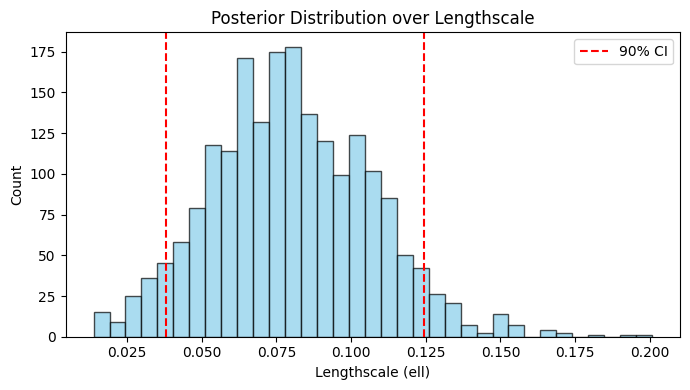

In [ ]:
X5 = jr.uniform(jr.PRNGKey(3), (5, 1))
y5 = f(X5)

def log_posterior(theta):
    ell, sf = jnp.exp(theta)
    prior = -0.5 * jnp.sum((theta - jnp.log(jnp.array([0.2, 1.0])))**2)


    return -nlml(ell, sf, X5, y5, k_SE) + prior


key = jr.PRNGKey(0)
current_theta = jnp.log(jnp.array([0.2, 1.0]))
chain_samples = []

print("Running MCMC chain...")
n_steps = 3000
accepted_count = 0

for step in range(n_steps):
    key, k_sub1, k_sub2 = jr.split(key, 3)


    proposal = current_theta + 0.5 * jr.normal(k_sub1, (2,))


    log_accept_ratio = log_posterior(proposal) - log_posterior(current_theta)

    if jnp.log(jr.uniform(k_sub2)) < log_accept_ratio:
        current_theta = proposal
        accepted_count += 1

    chain_samples.append(jnp.exp(current_theta))

print(f"Done! Acceptance rate: {accepted_count / n_steps:.2f}")

burn_in = 1000
ells = jnp.stack(chain_samples[burn_in:])[:, 0]

ci_90 = jnp.percentile(ells, jnp.array([5, 95]))
print(f"90% credible interval for lengthscale: [{ci_90[0]:.3f}, {ci_90[1]:.3f}]")


plt.figure(figsize=(7, 4))
plt.hist(ells, bins=35, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(float(ci_90[0]), color='red', linestyle='--', label='90% CI')
plt.axvline(float(ci_90[1]), color='red', linestyle='--')
plt.xlabel("Lengthscale (ell)")
plt.ylabel("Count")
plt.title("Posterior Distribution over Lengthscale")
plt.legend()
plt.tight_layout()
plt.show()

Kernel choice and fully Bayesian hyperparameters.


what is kernel: Baiscally it tell GP how funcation value are related to each other

What's important about this is that GP's mu and sigma control everything that happens
in any acquisition function in the Bayesian optimization loop.

These are determined by
the kernel and its parameters: ell determines the rate of variation while sf
determines the height of the function


Part 1 kernel comparison:

The length scale (ℓ) and the signal std (σ_f) were selected using a grid search approach, where multiple combinations of parameters were attempted, and the combination that produced the minimum NLML was retained.

The lower the NLML value, the better. NLML represents a tradeoff between two criteria: fit and complexity.


SE: ell = 0.094, sf = 0.672, NLML = -3.18
Matern 5/2: ell = 0.119, sf = 0.574, NLML = -1.66

SE model has a slightly higher NLML value suggesting that it fits your data better but this does not necessarily mean that the function is very smooth.

Part 2, fully Bayesian lengthscale:

Rather than finding a single optimal ell, we can used Metropolis Hastings on log(ell, sf) with
a Gaussian prior in log space, 3000 iterations, 1000 burn in
Acceptance rate was 0.40. The 90% credible interval for ell is
[0.038, 0.124] which means that ell is not very certain with only 5 data points
Value of SE found by grid search (0.094) lies within this interval.

Graph:

According to the histogram, the most probable value for the lengthscale is 0.08. However I think with just 5 data points we cannot be certain about the exact value.

It is possible for the lengthscale to lie somewhere between 0.038 and 0.124.